<a href="https://colab.research.google.com/github/Daumi-lab08/Analisis-Deret-Waktu/blob/main/Tugas_Minggu_8_Pendugaan_Parameter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1> TUGAS KELOMPOK </h1>

**<rjust> 1. Buatlah simulasi deret waktu (parameter yang digunakan bebas, tetapi berbeda dengan contoh yag sudah digunakan di atas) menggunakan seed 25xx, dimana xx adalah jumlah dua digit terakhir NIM anggota kelompok (misal NIM: 09 dan 28, maka seed yang digunakan 2537 . Lakukan pendugaan parameter menggunakan metode Kuadrat Terkecil dan Kemungkinan Maksimum:</rjust>**

**Kelompok 6: ARIMA (1,0,2) dan ARIMA (1,2,1)**






In [ ]:
# tentukan parameter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import least_squares
from statsmodels.tsa.arima.model import ARIMA

# Pengaturan simulasi
n = 300
seed = 2520
sigma = 1.0

# Parameter ARIMA(1,0,2)
phi_102 = 0.5
theta1_102 = 0.4
theta2_102 = -0.3

# Parameter ARIMA(1,2,1)
phi_121 = 0.4
theta1_121 = 0.5

print("Seed:", seed)
print("Panjang deret:", n)



Seed: 2520
Panjang deret: 300


,Waktu,Y
0,1,1.077701
1,2,0.539697
2,3,-0.569517
3,4,-0.891645
4,5,0.553416
5,6,0.566881
6,7,1.739400
7,8,1.385386
8,9,-2.191044
9,10,-1.027684


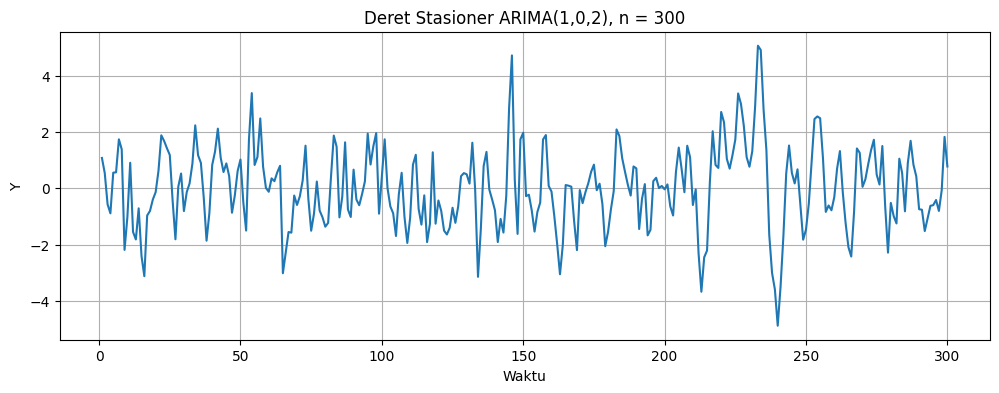

In [ ]:
# simulasi ARIMA (1,0,2)

np.random.seed(seed)

eps_102 = np.random.normal(0, sigma, n)
y_102 = np.zeros(n)

for t in range(n):
    ar = phi_102 * y_102[t-1] if t >= 1 else 0
    ma1 = theta1_102 * eps_102[t-1] if t >= 1 else 0
    ma2 = theta2_102 * eps_102[t-2] if t >= 2 else 0

    y_102[t] = ar + eps_102[t] + ma1 + ma2

data_102 = pd.DataFrame({
    "Waktu": np.arange(1, n+1),
    "Y": y_102
})

display(data_102.head(10))

plt.figure(figsize=(12, 4))
plt.plot(data_102["Waktu"], data_102["Y"])
plt.title("Deret Stasioner ARIMA(1,0,2), n = 300")
plt.xlabel("Waktu")
plt.ylabel("Y")
plt.grid(True)
plt.show()



,Waktu,Y
0,1,1.077701
1,2,2.695100
2,3,3.969299
3,4,4.335865
4,5,5.175590
5,6,6.428781
6,7,9.609587
7,8,14.167473
8,9,16.936553
9,10,18.733746


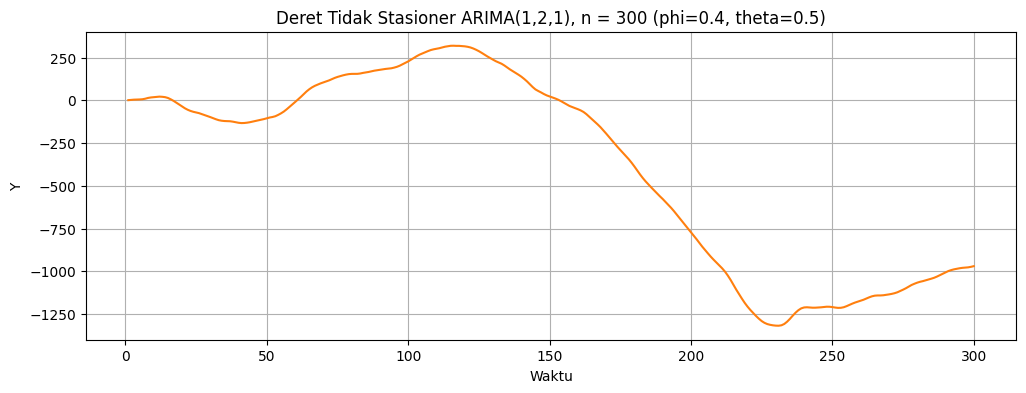

In [ ]:
# Simulasi ARIMA(1,2,1) dengan phi = 0.4 dan theta = 0.5
np.random.seed(seed)

# Bangkitkan inovasi (noise)
eps_121 = np.random.normal(0, sigma, n)
w_121 = np.zeros(n)

# Proses ARMA(1,1) sebagai selisih kedua
for t in range(n):
    ar = phi_121 * w_121[t-1] if t >= 1 else 0
    ma = theta1_121 * eps_121[t-1] if t >= 1 else 0
    w_121[t] = ar + eps_121[t] + ma

# Integrasi dua kali untuk mendapatkan ARIMA(1,2,1) - Tidak Stasioner
y_121 = np.cumsum(np.cumsum(w_121))

data_121 = pd.DataFrame({
    "Waktu": np.arange(1, n+1),
    "Y": y_121
})

# Tampilkan 10 data pertama
display(data_121.head(10))

# Visualisasi Plot Deret Waktu Tidak Stasioner
plt.figure(figsize=(12, 4))
plt.plot(data_121["Waktu"], data_121["Y"], color="tab:orange", linewidth=1.5)
plt.title("Deret Tidak Stasioner ARIMA(1,2,1), n = 300 (phi=0.4, theta=0.5)")
plt.xlabel("Waktu")
plt.ylabel("Y")
plt.grid(True)
plt.show()

In [ ]:
# Pendugaan parameter ARIMA(1,0,2)
# Menggunakan residual rekursif untuk Least Squares (KT)
def residual_arima_102(params, x):
    phi = params[0]
    theta1 = params[1]
    theta2 = params[2]
    residual = np.zeros(len(x))
    for t in range(len(x)):
        ar = phi * x[t-1] if t >= 1 else 0.0
        ma1 = theta1 * residual[t-1] if t >= 1 else 0.0
        ma2 = theta2 * residual[t-2] if t >= 2 else 0.0
        residual[t] = x[t] - ar - ma1 - ma2
    return residual

# 1. Metode Kuadrat Terkecil (Least Squares) dengan lambda untuk mengoper y_102
fit_ls_102 = least_squares(
    lambda params: residual_arima_102(params, y_102),
    x0=[0.2, 0.1, 0.1],
    max_nfev=10000
)

# 2. Metode Kemungkinan Maksimum (MLE)
fit_mle_102 = ARIMA(
    y_102,
    order=(1, 0, 2),
    trend="n"
).fit()

# Menyusun tabel perbandingan
tabel_perbandingan_102 = pd.DataFrame({
    "Parameter": ["AR(1) (phi)", "MA(1) (theta1)", "MA(2) (theta2)"],
    "Nilai Sebenarnya": [phi_102, theta1_102, theta2_102],
    "Duga KT (Least Squares)": fit_ls_102.x,
    "Duga KM (MLE)": [
        fit_mle_102.arparams[0],
        fit_mle_102.maparams[0],
        fit_mle_102.maparams[1]
    ]
})

print("PERBANDINGAN ESTIMASI PARAMETER ARIMA(1,0,2):")
display(tabel_perbandingan_102.round(4))

PERBANDINGAN ESTIMASI PARAMETER ARIMA(1,0,2):


,Parameter,Nilai Sebenarnya,Duga KT (Least Squares),Duga KM (MLE)
0,AR(1) (phi),0.5,0.4823,0.4832
1,MA(1) (theta1),0.4,0.5027,0.5060
2,MA(2) (theta2),-0.3,-0.2418,-0.2454


Penduga KT dan KM memberikan hasil yang relatif berdekatan. Penduga AR(1) sedikit lebih rendah daripada nilai sebenarnya, sedangkan MA(1) lebih tinggi dan MA(2) lebih dekat ke nol. Dengan demikian, kedua metode memberikan hasil yang cukup berdekatan, tetapi ketepatannya berbeda untuk setiap parameter.

In [ ]:
# Pendugaan parameter ARIMA(1,2,1)
# Diferensiasi orde dua terlebih dahulu untuk data ARIMA(1,2,1)
diff2_y_121 = np.diff(y_121, n=2)

# Fungsi residual untuk ARMA(1,1)
def residual_arima_121(params, x):
    phi = params[0]
    theta1 = params[1]
    residual = np.zeros(len(x))
    for t in range(len(x)):
        ar = phi * x[t-1] if t >= 1 else 0.0
        ma1 = theta1 * residual[t-1] if t >= 1 else 0.0
        residual[t] = x[t] - ar - ma1
    return residual

# 1. Metode Kuadrat Terkecil (Least Squares) menggunakan data yang telah didiferensiasi
fit_ls_121 = least_squares(
    lambda params: residual_arima_121(params, diff2_y_121),
    x0=[0.2, 0.1],
    max_nfev=10000
)

# 2. Metode Kemungkinan Maksimum (MLE) menggunakan data asli dengan order=(1,2,1)
fit_mle_121 = ARIMA(
    y_121,
    order=(1, 2, 1),
    trend="n"
).fit()

# Menyusun tabel perbandingan
tabel_perbandingan_121 = pd.DataFrame({
    "Parameter": ["AR(1) (phi)", "MA(1) (theta1)"],
    "Nilai Sebenarnya": [phi_121, theta1_121],
    "Duga KT (Least Squares)": fit_ls_121.x,
    "Duga KM (MLE)": [
        fit_mle_121.arparams[0],
        fit_mle_121.maparams[0]
    ]
})

print("PERBANDINGAN ESTIMASI PARAMETER ARIMA(1,2,1):")
display(tabel_perbandingan_121.round(4))

PERBANDINGAN ESTIMASI PARAMETER ARIMA(1,2,1):


,Parameter,Nilai Sebenarnya,Duga KT (Least Squares),Duga KM (MLE)
0,AR(1) (phi),0.4,0.4384,0.4354
1,MA(1) (theta1),0.5,0.5576,0.5588


Penduga KT dan KM juga menghasilkan nilai yang relatif berdekatan. Penduga AR(1) dan MA(1) dari kedua metode lebih tinggi daripada nilai sebenarnya. Perbedaan penduga KT dan KM relatif kecil untuk kedua parameter.

In [ ]:
import pandas as pd

# Menambahkan kolom label model sebelum digabungkan
tabel_perbandingan_102_labeled = tabel_perbandingan_102.copy()
tabel_perbandingan_102_labeled.insert(0, 'Model', 'ARIMA(1,0,2)')

tabel_perbandingan_121_labeled = tabel_perbandingan_121.copy()
tabel_perbandingan_121_labeled.insert(0, 'Model', 'ARIMA(1,2,1)')

# Menggabungkan kedua tabel
hasil_gabungan = pd.concat([tabel_perbandingan_102_labeled, tabel_perbandingan_121_labeled], ignore_index=True)

# Menghitung selisih (error) estimasi terhadap nilai sebenarnya
hasil_gabungan['Error KT'] = hasil_gabungan['Duga KT (Least Squares)'] - hasil_gabungan['Nilai Sebenarnya']
hasil_gabungan['Error KM'] = hasil_gabungan['Duga KM (MLE)'] - hasil_gabungan['Nilai Sebenarnya']

print("TABEL GABUNGAN HASIL ESTIMASI PARAMETER:")
display(hasil_gabungan.round(4))

TABEL GABUNGAN HASIL ESTIMASI PARAMETER:


,Model,Parameter,Nilai Sebenarnya,Duga KT (Least Squares),Duga KM (MLE),Error KT,Error KM
0,"ARIMA(1,0,2)",AR(1) (phi),0.5,0.4823,0.4832,-0.0177,-0.0168
1,"ARIMA(1,0,2)",MA(1) (theta1),0.4,0.5027,0.5060,0.1027,0.1060
2,"ARIMA(1,0,2)",MA(2) (theta2),-0.3,-0.2418,-0.2454,0.0582,0.0546
3,"ARIMA(1,2,1)",AR(1) (phi),0.4,0.4384,0.4354,0.0384,0.0354
4,"ARIMA(1,2,1)",MA(1) (theta1),0.5,0.5576,0.5588,0.0576,0.0588


Kesimpulan:

Secara umum, pada kedua model, penduga KT dan KM memberikan hasil yang berdekatan. Pada ARIMA(1,0,2), penduga KT sedikit lebih dekat ke nilai sebenarnya untuk AR(1) dan MA(1), sedangkan KM lebih dekat untuk MA(2). Pada ARIMA(1,2,1), KT lebih dekat untuk AR(1), sedangkan KM lebih dekat untuk MA(1).

Pada ARIMA(1,0,2), KT memiliki absolute error lebih kecil untuk MA(1), sedangkan KM lebih kecil untuk AR(1) dan MA(2). Pada ARIMA(1,2,1), KT lebih kecil untuk MA(1), sedangkan KM lebih kecil untuk AR(1). Jadi, belum ada satu metode yang selalu menghasilkan pendugaan paling dekat untuk semua parameter.


**<rjust> 2. Ulangi langkah no.1 sebanyak 30 ulangan. Hitunglah bias dan ragam dari penduga parameter menggunakan metode Kuadrat Terkecil dan Kemungkinan Maksimum yang diperoleh dari 30 ulangan tersebut. Dan buatlah boxplot untuk memvisualisasikan bias dan ragam tersebut. Interpretasikan boxpot yang diperoleh </rjust>**

In [ ]:
import numpy as np
import pandas as pd
from scipy.optimize import least_squares
from statsmodels.tsa.arima.model import ARIMA
import warnings
warnings.filterwarnings('ignore')

# Parameter yang ditentukan
n = 300
B = 30
seed = 2520
sigma = 1.0

phi_sebenarnya = 0.5
theta1_sebenarnya = 0.4
theta2_sebenarnya = -0.3

# Fungsi residual untuk Kuadrat Terkecil (KT)
def residual_arima_102(params, x):
    phi = params[0]
    theta1 = params[1]
    theta2 = params[2]
    residual = np.zeros(len(x))
    for t in range(len(x)):
        ar = phi * x[t-1] if t >= 1 else 0.0
        ma1 = theta1 * residual[t-1] if t >= 1 else 0.0
        ma2 = theta2 * residual[t-2] if t >= 2 else 0.0
        residual[t] = x[t] - ar - ma1 - ma2
    return residual

# Simulasi 30 Ulangan
rng = np.random.RandomState(seed)
hasil_simulasi = []

for u in range(1, B + 1):
    # Bangkitkan inovasi dan data deret waktu ARIMA(1,0,2)
    eps = rng.normal(0, sigma, n)
    y = np.zeros(n)
    for t in range(n):
        ar = phi_sebenarnya * y[t-1] if t >= 1 else 0.0
        ma1 = theta1_sebenarnya * eps[t-1] if t >= 1 else 0.0
        ma2 = theta2_sebenarnya * eps[t-2] if t >= 2 else 0.0
        y[t] = ar + eps[t] + ma1 + ma2

    # Pendugaan parameter dengan Least Squares (KT)
    fit_ls = least_squares(
        lambda params: residual_arima_102(params, y),
        x0=[0.2, 0.1, 0.1],
        max_nfev=10000
    )

    # Pendugaan parameter dengan MLE (KM)
    fit_mle = ARIMA(y, order=(1, 0, 2), trend='n').fit()

    hasil_simulasi.append({
        'Ulangan': u,
        'KT_AR1 (phi)': fit_ls.x[0],
        'KM_AR1 (phi)': fit_mle.arparams[0],
        'KT_MA1 (theta1)': fit_ls.x[1],
        'KM_MA1 (theta1)': fit_mle.maparams[0],
        'KT_MA2 (theta2)': fit_ls.x[2],
        'KM_MA2 (theta2)': fit_mle.maparams[1]
    })

# Membuat DataFrame dari seluruh hasil pendugaan
df_hasil_30 = pd.DataFrame(hasil_simulasi)

# Menghitung Statistik Ringkasan (Rata-rata, Bias, Ragam)
stats_ringkasan = pd.DataFrame({
    'Parameter': ['AR(1) (phi)', 'MA(1) (theta1)', 'MA(2) (theta2)'],
    'Nilai Sebenarnya': [phi_sebenarnya, theta1_sebenarnya, theta2_sebenarnya],
    'Rata-rata KT': [df_hasil_30['KT_AR1 (phi)'].mean(), df_hasil_30['KT_MA1 (theta1)'].mean(), df_hasil_30['KT_MA2 (theta2)'].mean()],
    'Rata-rata KM': [df_hasil_30['KM_AR1 (phi)'].mean(), df_hasil_30['KM_MA1 (theta1)'].mean(), df_hasil_30['KM_MA2 (theta2)'].mean()],
    'Bias KT': [df_hasil_30['KT_AR1 (phi)'].mean() - phi_sebenarnya, df_hasil_30['KT_MA1 (theta1)'].mean() - theta1_sebenarnya, df_hasil_30['KT_MA2 (theta2)'].mean() - theta2_sebenarnya],
    'Bias KM': [df_hasil_30['KM_AR1 (phi)'].mean() - phi_sebenarnya, df_hasil_30['KM_MA1 (theta1)'].mean() - theta1_sebenarnya, df_hasil_30['KM_MA2 (theta2)'].mean() - theta2_sebenarnya],
    'Ragam KT': [df_hasil_30['KT_AR1 (phi)'].var(), df_hasil_30['KT_MA1 (theta1)'].var(), df_hasil_30['KT_MA2 (theta2)'].var()],
    'Ragam KM': [df_hasil_30['KM_AR1 (phi)'].var(), df_hasil_30['KM_MA1 (theta1)'].var(), df_hasil_30['KM_MA2 (theta2)'].var()]
})

print("=== 30 NILAI PENDUGAAN PARAMETER ARIMA(1,0,2) ===")
display(df_hasil_30.round(4))

print("\n=== RINGKASAN BIAS DAN RAGAM ===")
display(stats_ringkasan.round(5))

=== 30 NILAI PENDUGAAN PARAMETER ARIMA(1,0,2) ===


,Ulangan,KT_AR1 (phi),KM_AR1 (phi),KT_MA1 (theta1),KM_MA1 (theta1),KT_MA2 (theta2),KM_MA2 (theta2)
0,1,0.4823,0.4832,0.5027,0.5060,-0.2418,-0.2454
1,2,-0.4639,-0.4589,1.3913,1.3834,0.4953,0.4893
2,3,0.4468,0.4398,0.4397,0.4477,-0.2963,-0.2894
3,4,0.4952,0.4922,0.4011,0.4010,-0.2750,-0.2708
4,5,0.6847,0.6854,0.2015,0.2015,-0.4890,-0.4876
5,6,-0.5749,-0.6069,1.4336,1.4681,0.5679,0.5944
6,7,-0.5817,-0.6073,1.4787,1.5020,0.5648,0.5851
7,8,0.3652,0.3651,0.4763,0.4737,-0.1549,-0.1546
8,9,0.3730,0.3705,0.5177,0.5198,-0.2060,-0.2045
9,10,0.5625,0.5452,0.3059,0.3214,-0.4442,-0.4282



=== RINGKASAN BIAS DAN RAGAM ===


,Parameter,Nilai Sebenarnya,Rata-rata KT,Rata-rata KM,Bias KT,Bias KM,Ragam KT,Ragam KM
0,AR(1) (phi),0.5,0.37691,0.34491,-0.12309,-0.15509,0.16836,0.16170
1,MA(1) (theta1),0.4,0.50608,0.54037,0.10608,0.14037,0.18051,0.17196
2,MA(2) (theta2),-0.3,-0.20116,-0.17401,0.09884,0.12599,0.11940,0.11224


In [ ]:
import numpy as np
import pandas as pd
from scipy.optimize import least_squares
from statsmodels.tsa.arima.model import ARIMA
import warnings
warnings.filterwarnings('ignore')

# Parameter yang ditentukan
n = 300
B = 30
seed = 2520
sigma = 1.0

phi_121_seb = 0.4
theta1_121_seb = 0.5

# Fungsi residual untuk ARMA(1,1) setelah diferensiasi
def residual_arima_121(params, x):
    phi = params[0]
    theta1 = params[1]
    residual = np.zeros(len(x))
    for t in range(len(x)):
        ar = phi * x[t-1] if t >= 1 else 0.0
        ma1 = theta1 * residual[t-1] if t >= 1 else 0.0
        residual[t] = x[t] - ar - ma1
    return residual

# Simulasi 30 Ulangan untuk ARIMA(1,2,1)
rng = np.random.RandomState(seed)
hasil_simulasi_121 = []

for u in range(1, B + 1):
    # Bangkitkan inovasi dan data ARIMA(1,2,1)
    eps = rng.normal(0, sigma, n)
    w = np.zeros(n)
    for t in range(n):
        ar = phi_121_seb * w[t-1] if t >= 1 else 0.0
        ma1 = theta1_121_seb * eps[t-1] if t >= 1 else 0.0
        w[t] = ar + eps[t] + ma1

    # Integrasi dua kali agar menjadi ARIMA(1,2,1)
    y = np.cumsum(np.cumsum(w))

    # Diferensiasi orde dua untuk estimasi Least Squares (KT)
    diff2_y = np.diff(y, n=2)

    # Estimasi dengan Least Squares (KT)
    fit_ls = least_squares(
        lambda params: residual_arima_121(params, diff2_y),
        x0=[0.2, 0.1],
        max_nfev=10000
    )

    # Estimasi dengan MLE (KM)
    fit_mle = ARIMA(y, order=(1, 2, 1), trend='n').fit()

    hasil_simulasi_121.append({
        'Ulangan': u,
        'KT_AR1 (phi)': fit_ls.x[0],
        'KM_AR1 (phi)': fit_mle.arparams[0],
        'KT_MA1 (theta1)': fit_ls.x[1],
        'KM_MA1 (theta1)': fit_mle.maparams[0]
    })

# Membuat DataFrame untuk 30 hasil estimasi
df_hasil_121 = pd.DataFrame(hasil_simulasi_121)

# Menghitung Statistik Ringkasan (Rata-rata, Bias, Ragam) untuk ARIMA(1,2,1)
stats_ringkasan_121 = pd.DataFrame({
    'Parameter': ['AR(1) (phi)', 'MA(1) (theta1)'],
    'Nilai Sebenarnya': [phi_121_seb, theta1_121_seb],
    'Rata-rata KT': [df_hasil_121['KT_AR1 (phi)'].mean(), df_hasil_121['KT_MA1 (theta1)'].mean()],
    'Rata-rata KM': [df_hasil_121['KM_AR1 (phi)'].mean(), df_hasil_121['KM_MA1 (theta1)'].mean()],
    'Bias KT': [df_hasil_121['KT_AR1 (phi)'].mean() - phi_121_seb, df_hasil_121['KT_MA1 (theta1)'].mean() - theta1_121_seb],
    'Bias KM': [df_hasil_121['KM_AR1 (phi)'].mean() - phi_121_seb, df_hasil_121['KM_MA1 (theta1)'].mean() - theta1_121_seb],
    'Ragam KT': [df_hasil_121['KT_AR1 (phi)'].var(), df_hasil_121['KT_MA1 (theta1)'].var()],
    'Ragam KM': [df_hasil_121['KM_AR1 (phi)'].var(), df_hasil_121['KM_MA1 (theta1)'].var()]
})

print("=== 30 NILAI PENDUGAAN PARAMETER ARIMA(1,2,1) ===")
display(df_hasil_121.round(4))

print("\n=== RINGKASAN BIAS DAN RAGAM ARIMA(1,2,1) ===")
display(stats_ringkasan_121.round(5))

=== 30 NILAI PENDUGAAN PARAMETER ARIMA(1,2,1) ===


,Ulangan,KT_AR1 (phi),KM_AR1 (phi),KT_MA1 (theta1),KM_MA1 (theta1)
0,1,0.4384,0.4354,0.5576,0.5588
1,2,0.3135,0.3134,0.5918,0.6018
2,3,0.3827,0.3808,0.4966,0.4961
3,4,0.4558,0.4529,0.4274,0.4283
4,5,0.3373,0.3330,0.5424,0.5538
5,6,0.3965,0.3946,0.4485,0.4483
6,7,0.3242,0.3332,0.5721,0.5701
7,8,0.4286,0.4281,0.4017,0.4017
8,9,0.4300,0.4308,0.4396,0.4403
9,10,0.2868,0.2960,0.5515,0.5758



=== RINGKASAN BIAS DAN RAGAM ARIMA(1,2,1) ===


,Parameter,Nilai Sebenarnya,Rata-rata KT,Rata-rata KM,Bias KT,Bias KM,Ragam KT,Ragam KM
0,AR(1) (phi),0.4,0.39440,0.39436,-0.00560,-0.00564,0.00346,0.00338
1,MA(1) (theta1),0.5,0.48379,0.48527,-0.01621,-0.01473,0.00431,0.00464


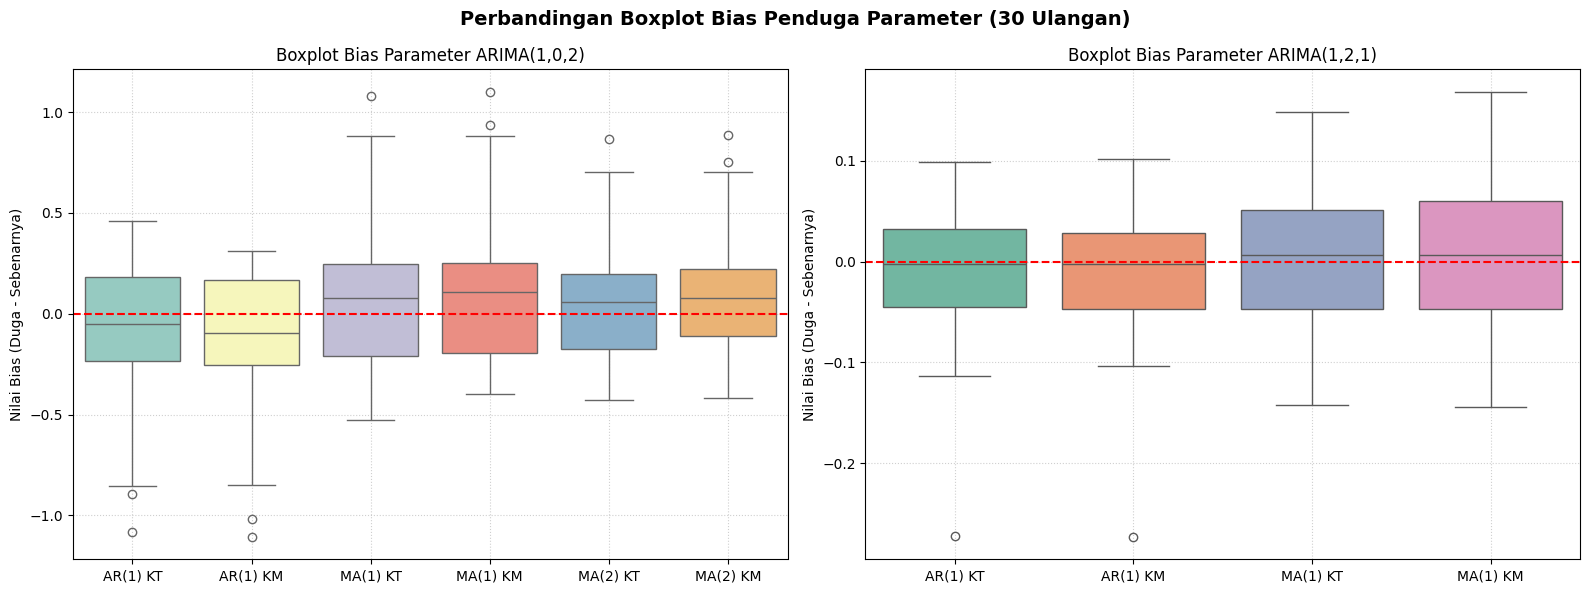

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Menghitung bias/error untuk ARIMA(1,0,2)
bias_arima_102 = pd.DataFrame({
    'AR(1) KT': df_102['KT_AR1'] - 0.5,
    'AR(1) KM': df_102['KM_AR1'] - 0.5,
    'MA(1) KT': df_102['KT_MA1'] - 0.4,
    'MA(1) KM': df_102['KM_MA1'] - 0.4,
    'MA(2) KT': df_102['KT_MA2'] - (-0.3),
    'MA(2) KM': df_102['KM_MA2'] - (-0.3)
})

# Menghitung bias/error untuk ARIMA(1,2,1)
bias_arima_121 = pd.DataFrame({
    'AR(1) KT': df_121['KT_AR1'] - 0.4,
    'AR(1) KM': df_121['KM_AR1'] - 0.4,
    'MA(1) KT': df_121['KT_MA1'] - 0.5,
    'MA(1) KM': df_121['KM_MA1'] - 0.5
})

# Membuat plot berdampingan
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot ARIMA(1,0,2)
sns.boxplot(data=bias_arima_102, ax=axes[0], palette="Set3")
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_title("Boxplot Bias Parameter ARIMA(1,0,2)", fontsize=12)
axes[0].set_ylabel("Nilai Bias (Duga - Sebenarnya)")
axes[0].grid(True, linestyle=':', alpha=0.6)

# Plot ARIMA(1,2,1)
sns.boxplot(data=bias_arima_121, ax=axes[1], palette="Set2")
axes[1].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_title("Boxplot Bias Parameter ARIMA(1,2,1)", fontsize=12)
axes[1].set_ylabel("Nilai Bias (Duga - Sebenarnya)")
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.suptitle("Perbandingan Boxplot Bias Penduga Parameter (30 Ulangan)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

1. **Analisis Boxplot ARIMA(1,0,2) (Kiri)**

Penduga AR(1) (KT & KM) memiliki rentang boxplot yang sedikit lebih lebar
dengan beberapa pencilan (outliers) di sisi bawah (negatif), mengindikasikan sesekali adanya estimasi yang bernilai jauh di bawah nilai sebenarnya

Penduga MA(1) dan MA(2) memiliki median bias yang sangat dekat dengan garis putus-putus merah (Bias = 0), meskipun distribusinya sedikit condong ke arah positif (overestimate).

Perbandingan KT vs KM: Distribusi boxplot antara metode Kuadrat Terkecil (KT) dan MLE (KM) terlihat hampir identik secara visual, mempertegas bahwa tidak ada perbedaan performa yang signifikan antara kedua metode untuk model stasioner ini pada ukuran sampel n=300 dan 30 ulangan.

2. **Analisis Boxplot ARIMA(1,2,1) (Kanan)**

Akurasi yang Sangat Tinggi:
Rentang sumbu Y untuk ARIMA(1,2,1) jauh lebih sempit (presisi) dibandingkan ARIMA(1,0,2) yang menunjukkan tingkat ragam (variance) yang sangat kecil.

Pemusatan Nilai: Median bias dari kedua parameter, baik untuk AR(1) maupun MA(1), berada sangat dekat dengan nilai nol. Hal ini menunjukkan bahwa melakukan diferensiasi sebanyak 2 kali sebelum melakukan estimasi parameter sangat efektif dalam menghasilkan penduga yang tidak bias (unbiased) dan konsisten.